# PoC do rio Culm
Execute após preparar a imagem e as dependências no README. A raiz é determinada a partir do diretório do notebook. HOMETEL e SYSTELCFG são internos ao contêiner e definidos no Dockerfile. Os dados são cópias do exemplo telemac2d/culm.

In [1]:
import os, sys, subprocess, json
from pathlib import Path
from IPython.display import Image, display
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'poc/steady.cas').exists())
env = dict(os.environ, PYTHONPATH=os.pathsep.join(map(str,[root,root/'tapajos-telemac-platform'])))
def run(*args):
    subprocess.run([sys.executable,*args],cwd=root,env=env,check=True)
print((root/'poc/parameters.json').read_text())

{
  "image": "tapajos-telemac:source",
  "steps": 600,
  "print_period": 60,
  "dispersion_m2_s": 0.5,
  "diameter_m": 0.001,
  "steady_depth_rate": 1e-05,
  "steady_velocity_rate": 1e-05,
  "steady_flux_fraction": 0.001,
  "cut_radius_m": 85,
  "cut_depth_m": 0.1,
  "steady_steps": 27000,
  "steady_print_period": 1000,
  "time_step_s": 2,
  "flow_m3_s": 28.32,
  "outlet_m": 23.77,
  "strickler": 30,
  "cut_center_m": [
    170,
    507
  ],
  "density_sediment": 2650,
  "porosity": 0.4,
  "shields": 0.047
}



## Batimetria e escrita Selafin

In [2]:
run('-m', 'unittest', 'discover', '-s', 'tests')

./Users/marcoabo/telemac_workspace/poc-checkout/tapajos-telemac-platform/backend/api/slf_io.py:47: ResourceWarning: unclosed file <_io.BufferedReader name='/Users/marcoabo/telemac_workspace/poc-checkout/tapajos-telemac-platform/data/culm/geo_culm.slf'>
  data = open(data, "rb").read()
/Users/marcoabo/telemac_workspace/poc-checkout/tapajos-telemac-platform/backend/api/slf_io.py:47: ResourceWarning: unclosed file <_io.BufferedReader name='/var/folders/pp/nxmjtm794jgd47c66mn777040000gn/T/tmps_g2dvp4/test.slf'>
  data = open(data, "rb").read()
.
----------------------------------------------------------------------
Ran 2 tests in 0.123s

OK


## Regime permanente e balanço

In [3]:
run('poc/run.py', 'steady')

{'time_s': np.float64(54000.0), 'rates': [np.float64(1.1051744222640991e-06), np.float64(3.529291599988937e-06), np.float64(2.093631774187088e-06)], 'flux_m3_s': [28.32, -28.31967]}


## Controle e injeção no contorno

In [4]:
run('poc/run.py', 'tracer')

## Evolução de fundo com GAIA

In [5]:
run('poc/run.py', 'bed')

## Dragagem com Nestor

In [6]:
run('poc/run.py', 'cut')

## Mapas e balanços

In [7]:
run('poc/analyse.py')

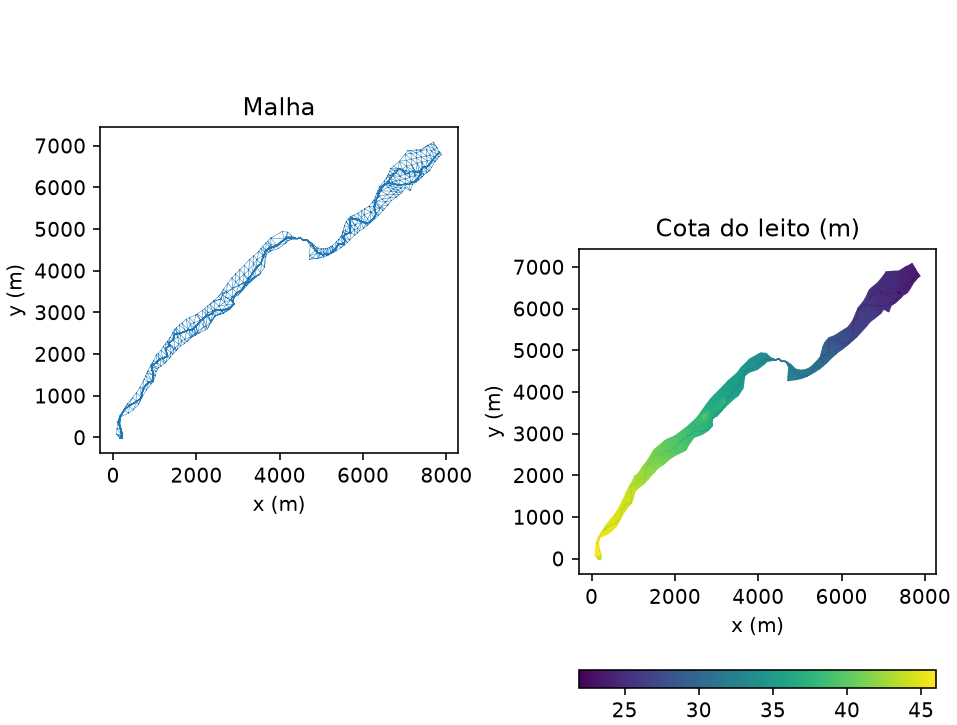

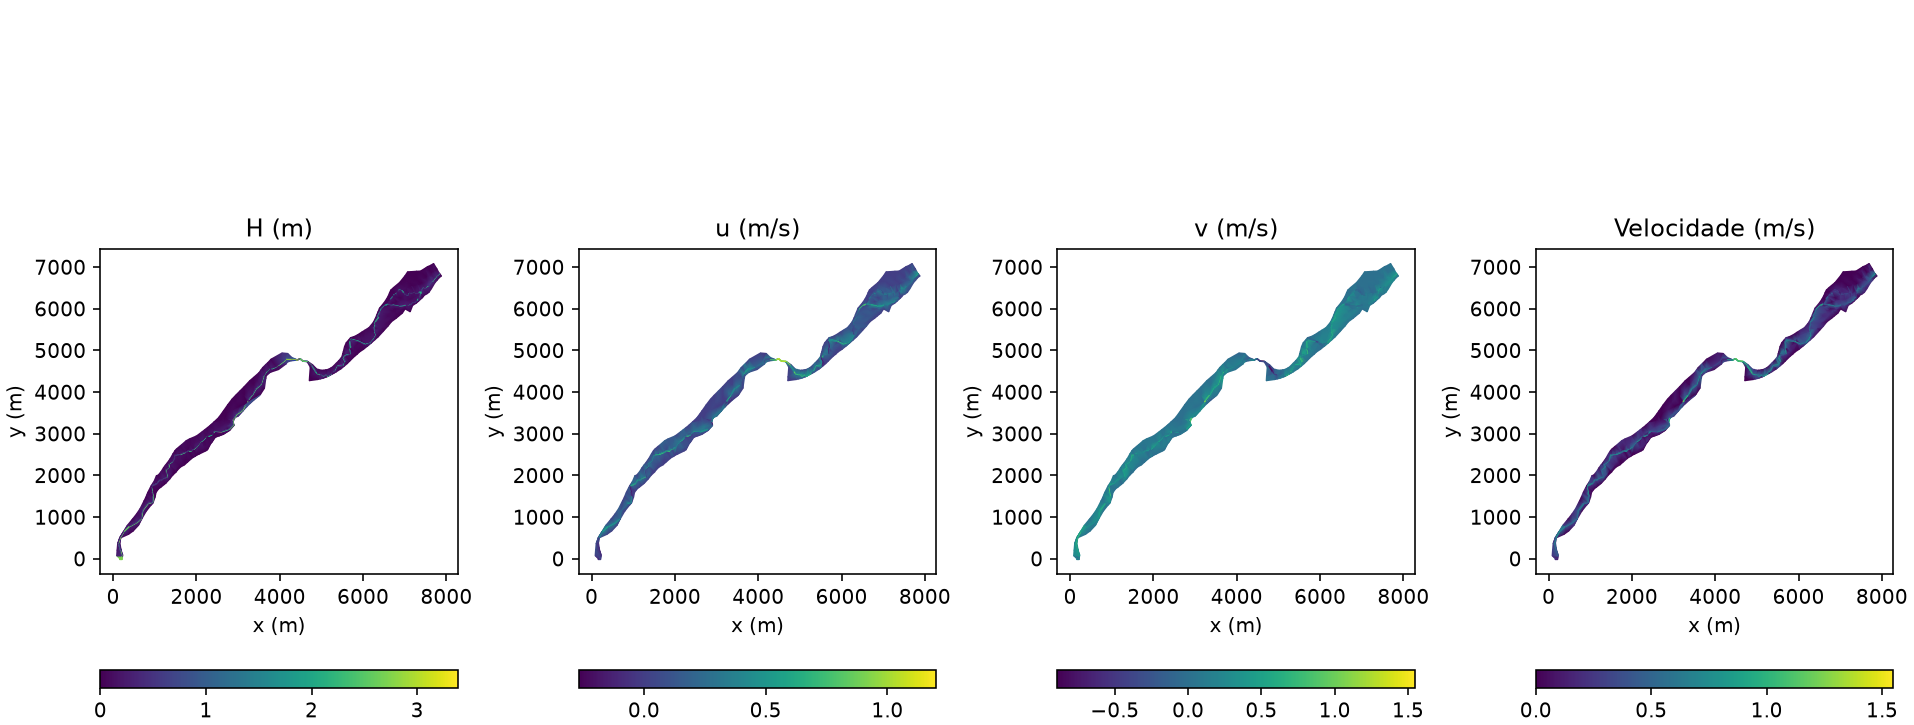

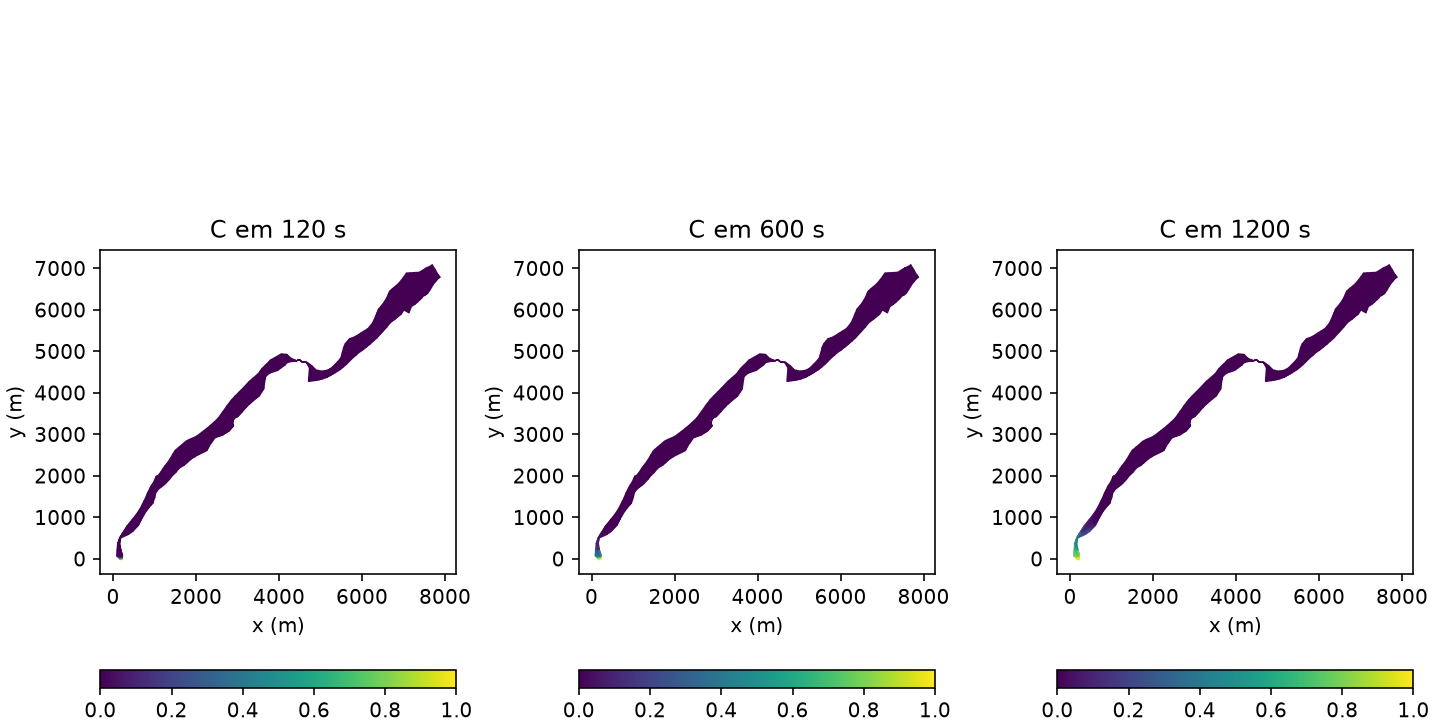

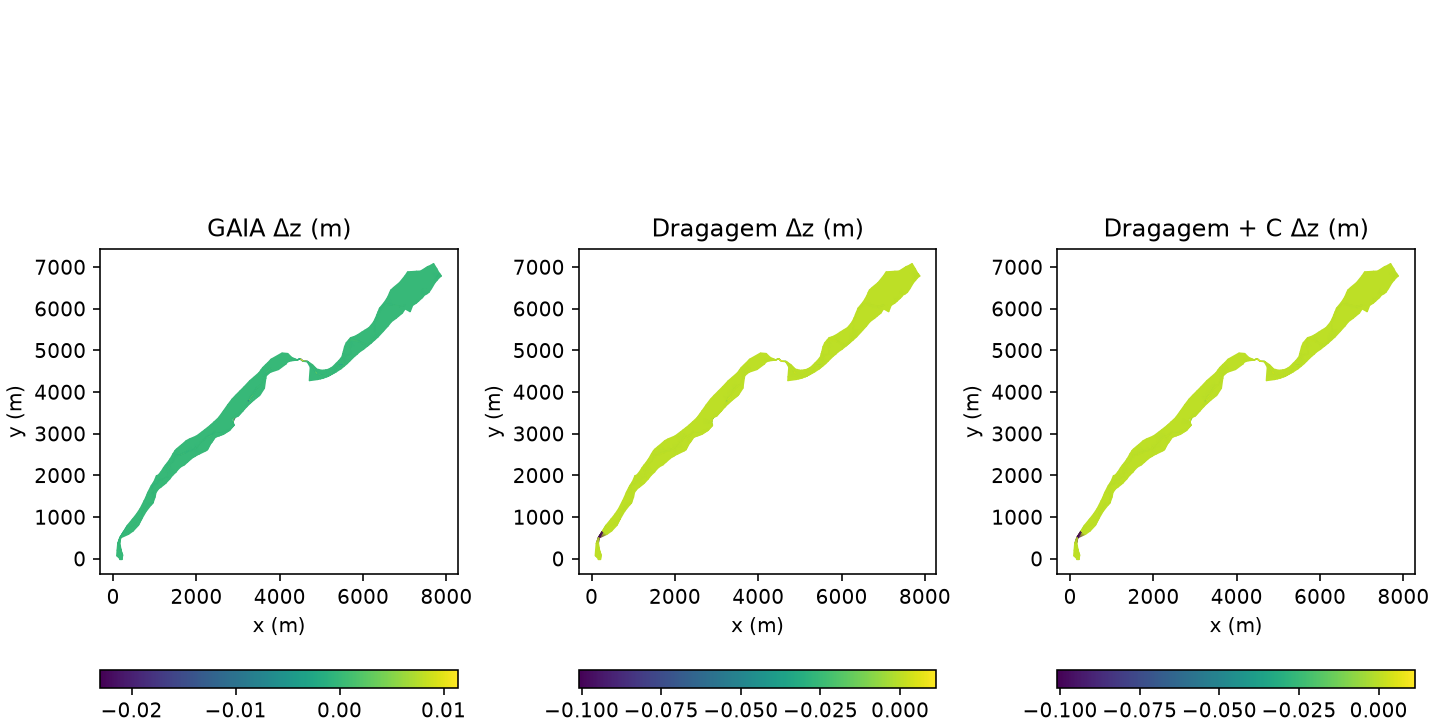

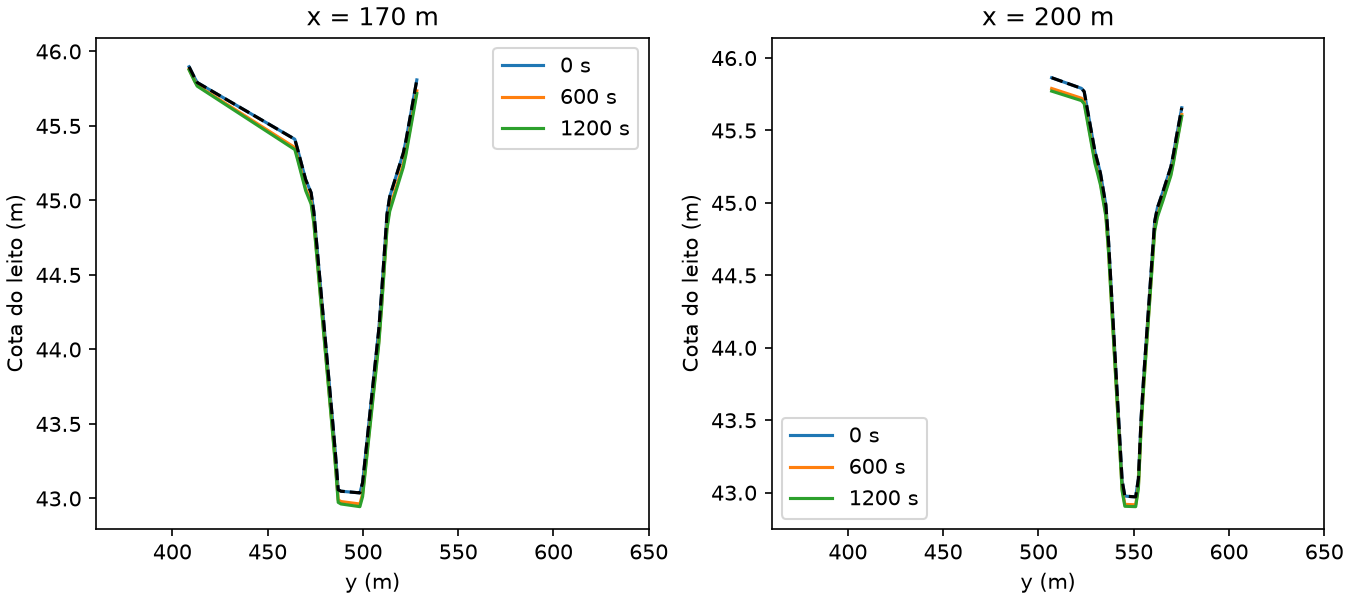

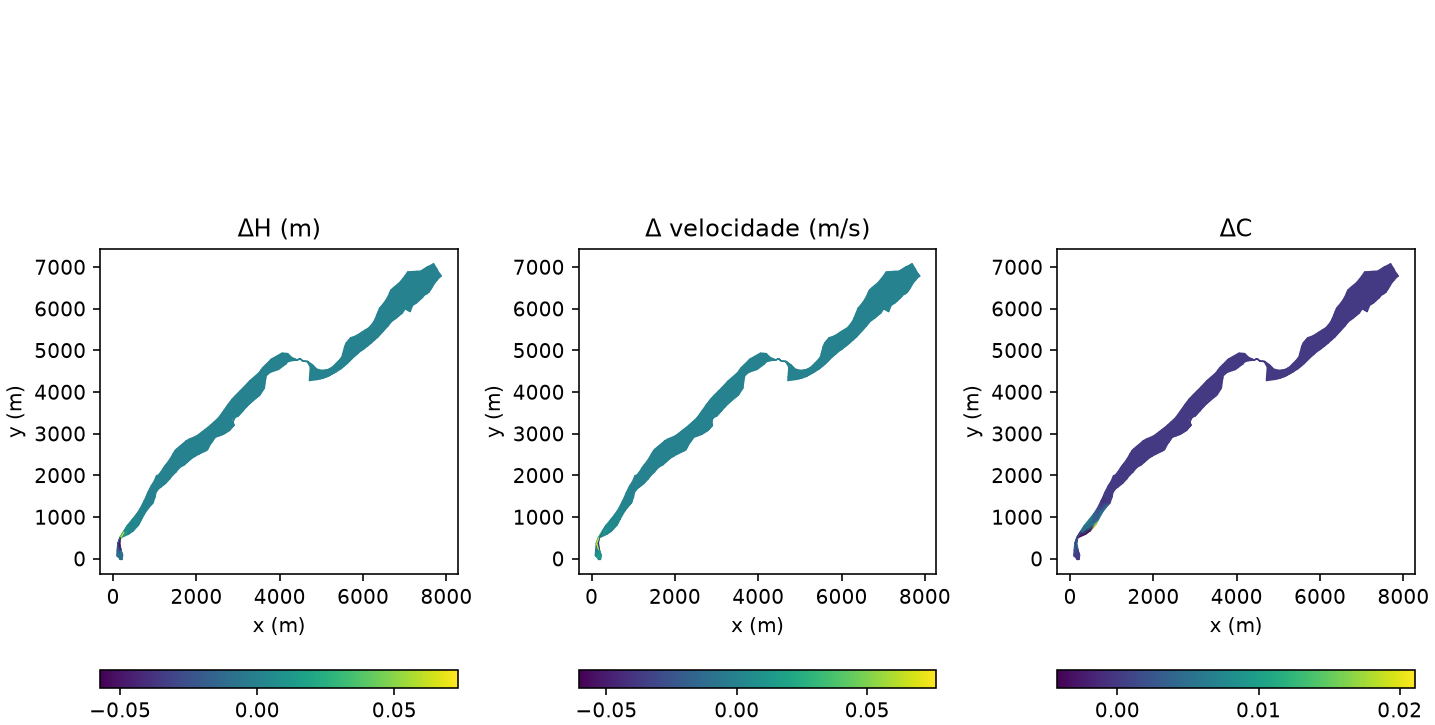

{
  "steady": {
    "time_s": 54000.0,
    "rates": [
      1.1051744222640991e-06,
      3.529291599988937e-06,
      2.093631774187088e-06
    ],
    "flux_m3_s": [
      28.32,
      -28.31967
    ]
  },
  "passivo": {
    "WATER DEPTH": {
      "max_abs": 0.0,
      "L2": 0.0
    },
    "VELOCITY U": {
      "max_abs": 0.0,
      "L2": 0.0
    },
    "VELOCITY V": {
      "max_abs": 0.0,
      "L2": 0.0
    },
    "tau": {
      "max_abs": 0.0,
      "L2": 0.0
    }
  },
  "fundo": {
    "tracer": {
      "max_abs": 0.0,
      "L2": 0.0
    },
    "bed": {
      "max_abs": 0.02300262451171875,
      "L2": 0.6390834691064788
    },
    "bed_dye": {
      "max_abs": 0.02300262451171875,
      "L2": 0.6390834691064788
    },
    "cut": {
      "max_abs": 0.10084915161132812,
      "L2": 9.001721383982982
    },
    "cut_dye": {
      "max_abs": 0.10084915161132812,
      "L2": 9.001721383982982
    }
  },
  "dragagem": {
    "BOTTOM": {
      "max_abs": 0.10007858276367188,
      "L2"

In [8]:
for name in ['geometria','hidro','pluma','leito','perfis','impacto']:
    display(Image(filename=str(root/f'poc/results/{name}.png')))
print((root/'poc/results/metricas.json').read_text())